<a href="https://colab.research.google.com/github/isha0902/Deep_learning/blob/main/1BM24CD022_Isha_Srivastava_Program_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6 — Bidirectional RNN for Music Generation
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** Treat a melody as a sequence of note *tokens*. A **two-layer Bidirectional LSTM**
reads the sequence and, at **every** time step, predicts the **next** note (a language-model
objective). After training we *generate* a new melody by predicting one note at a time and
sliding a window forward.

---
### How to use this notebook
Replace every `None  # TODO (Qn)` with the correct value or line of code. Run cells top to
bottom. Cells marked *(given — do not edit)* set things up for you.

> **Heads-up (you will analyse this):** the dataset here is *random* notes. Watch the accuracy
> and ask yourself in Task 7 whether it really means the model learned music.


## Step 0 — Imports *(given — do not edit)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Build the dataset (next-token pairs)

We have `num_sequences` melodies, each `sequence_length` notes long, drawn from a vocabulary of
`num_notes` distinct notes. Turn each melody into an **(input, target)** pair where the target is
the input **shifted left by one** (predict the next note), then **one-hot encode** both.

*Hints:* the input is every note **except the last**; the target is every note **except the
first**. One-hot vectors have length `num_notes`.


In [2]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data [: , : -1]   # TODO (Q1a): data[:, :-1]
y_train = data [: , 1:] # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = 50  # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


#### Quick check *(given — run to verify Task 1)*

In [3]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the Bidirectional LSTM model

Build a `Sequential` model with:
1. an **Input** of shape `(sequence_length-1, num_notes)` = `(29, 50)`;
2. **two Bidirectional LSTM layers**, 128 units each, **returning sequences** (an output at every
   step);
3. a **TimeDistributed Dense** output with `num_notes` units and **softmax** — one shared
   per-step note classifier.

*Hints:* a bidirectional layer is `layers.Bidirectional(layers.LSTM(units, return_sequences=...))`.
With 128 units per direction the layer outputs `2 * 128 = 256` features per step.


In [4]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** From the summary, the first Bi-LSTM shows **183,296** parameters. Verify
it by hand with `2 * 4 * [(features + units) * units + units]`, where `features = 50`,
`units = 128`. Then explain why the **second** Bi-LSTM has *more* parameters than the first.

> **Your answer (Q2d):** params = 2 × 4 × [ (____ + ____) × ____ + ____ ] = ________ ;
> the second layer is larger because ____.


## Task 3 — Compile and train

Compile with the **Adam** optimiser (learning rate `0.001`), **categorical crossentropy** loss
(targets are one-hot), and track **accuracy**. Train for 20 epochs, batch size 64, holding out
20% for validation.


In [7]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                           # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=20,            # TODO (Q3b): 20
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 379ms/step - accuracy: 0.1011 - loss: 3.8851 - val_accuracy: 0.1614 - val_loss: 3.8454
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 303ms/step - accuracy: 0.1339 - loss: 3.7739 - val_accuracy: 0.0855 - val_loss: 3.6732
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 353ms/step - accuracy: 0.1157 - loss: 3.5290 - val_accuracy: 0.1331 - val_loss: 3.4126
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 296ms/step - accuracy: 0.1600 - loss: 3.2522 - val_accuracy: 0.1748 - val_loss: 3.1213
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 356ms/step - accuracy: 0.2056 - loss: 2.9202 - val_accuracy: 0.2314 - val_loss: 2.7754
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step - accuracy: 0.2680 - loss: 2.5431 - val_accuracy: 0.2983 - val_loss: 2.3816
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 299ms/step - accuracy: 0.3426 - loss: 2.1590 - val_accuracy: 0.3721 - val_loss: 2.0105
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 378ms/step - accuracy: 0.4242 - loss: 1.7912 - val_accuracy: 0

## Task 4 — Plot the training history *(fill the blanks)*

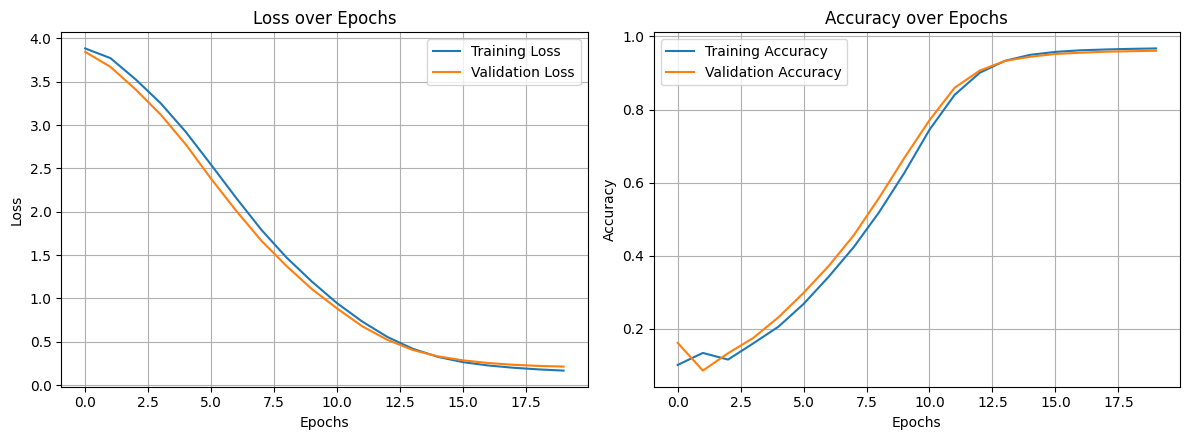

In [9]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

## Task 5 — Generate a new sequence (greedy decoding)

Complete the generation loop: predict with the model, read the distribution at the **last** time
step, take the most likely note (`argmax`), append it, then **slide the window** by dropping the
first step and appending the new note (one-hot).


In [14]:

def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence

    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)

        # Q5a) Pick the most likely note at the LAST time step
        next_note = np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) Slide the window
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence = np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated


# Seed window
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)


Generated: [25, 25, 25, 25, 25, 25, 25, 25, 9, 9, 9, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35, 35]


## Task 6 — Piano-roll of the generated melody *(fill one blank)*

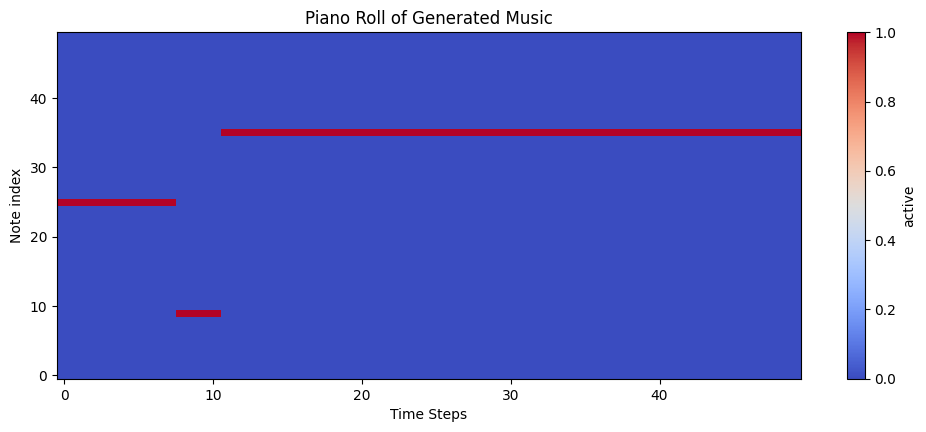

In [15]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1  # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

## Task 7 — Analysis *(write your answers here)*

1. The two Bi-LSTM layers both use `return_sequences=True`. What would break if you set it to
   `False` on the first layer?
2. Why is the first Bi-LSTM's output width **256** when the LSTM has 128 units?
3. What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?
4. You trained on **random** notes, yet accuracy reaches ~96%. **Explain the mechanism.**
   *(Hint: the target at step t equals the input at step t+1 — which direction of a bidirectional
   layer can already see it?)*
5. Why is a **bidirectional** model a poor choice for *autoregressive generation*, and what two
   changes would make this an honest music generator?

> **Your answers:**
>1. The first Bi-LSTM would return only the final output instead of the full sequence, causing the second Bi-LSTM to receive an invalid input shape.

> 2.Because forward and backward LSTMs each have 128 units. Their outputs are concatenated: 128 + 128 = 256.

> 3.TimeDistributed(Dense(50)) applies the same Dense layer independently to every time step, producing 50 outputs per step.

> 4.The backward LSTM can see future inputs, including the target note at the next time step. This causes data leakage and artificially high accuracy.

> 5.A bidirectional model uses future information, which is unavailable during generation. To fix it:
- Use unidirectional LSTM layers.
- Shift the target sequence to predict the next note using only past notes.


## (Optional) Stretch — make it causal
Copy the model into a new cell, remove **both** `Bidirectional` wrappers (plain `LSTM`), retrain,
and compare the accuracy curve. Explain why the (lower) number is the more honest one.


In [17]:
import numpy as np
from IPython.display import Audio, display

sample_rate = 44100
note_duration = 0.25

audio_waveform = np.array([], dtype=np.float32)

for note_token in generated_music:
    midi_pitch = note_token + 48
    freq = 440.0 * (2.0 ** ((midi_pitch - 69) / 12.0))
    t = np.linspace(0, note_duration, int(sample_rate * note_duration), endpoint=False)
    envelope = np.minimum(t * 50, 1.0) * np.minimum((note_duration - t) * 50, 1.0)
    tone = 0.4 * envelope * np.sin(2 * np.pi * freq * t)
    audio_waveform = np.concatenate((audio_waveform, tone))
display(Audio(audio_waveform, rate=sample_rate))